# Validation questions — ownership-breadth factor

A running set of questions about the factor's efficacy and the data behind it. Each
answer states the result first and ends with a chart or table that shows it.

**The factor:** the out-of-sample score of the 16-feature LightGBM model (13 breadth
features + size/value), from the purged & embargoed 5-fold CV used in the README
(12-month label) — the README's full model. Its size/value inputs come from **point-in-time**
market caps (as-traded price × SEC share count, share-count checked), so its mean rank IC is
**0.0645** (t 5.5). An earlier version of the pipeline reported 0.072, because its caps used split-
and dividend-adjusted prices, which leak the future; this notebook found that bug and measures it
(Q7). The incremental IC from breadth is +0.0095 either way.

**Findings at a glance**

| # | Question | Short answer |
|---|---|---|
| 1 | Are decile returns monotonic? | **No — the factor is top-heavy.** D1 beats the universe by 6.8% over 12 months, in 76% of quarters; D2–D10 means are flat. Medians do fall toward D10. |
| 2 | Which features survived? | 9 of 16 at 12 months (and at 6). Size/value have the largest SHAP values; position-size dispersion, top-10 concentration and aggregate institutional shares lead the breadth features. |
| 3 | Momentum proxy? | **No.** ~0 correlation with 12-1 momentum, and 90% of IC survives removing it. Size, though, explains most of the breadth-only score. |
| 4 | Regime-dependent? | IC is higher when the 10-year yield is rising (0.089 vs 0.036; p ≈ 0.03 before adjusting for overlap). The level of rates doesn't matter. |
| 5 | Stable deciles? | Extremes are sticky (D1 keeps 55% of names quarter-on-quarter), the middle churns. About 44% of D1 is replaced each quarter. |
| 6 | Cap- vs equal-weighted L/S? | Neither works reliably. EW D1−D10 earns +4%/yr (not significant); on names with trustworthy caps both EW and VW are about −7%/yr. The long leg is the robust part. |
| 7 | Are the size/value inputs point-in-time? | **Now yes; originally no — a real look-ahead, since fixed.** Adjusted prices had understated 10% of caps by ≥1.5× (AMZN 20×, NVDA 39× in 2019). The fix cut the full model's IC from 0.072 to 0.0645; breadth's +0.0095 increment is unchanged. |
| 8 | Are SEC share counts sane? | 2.8% of stock-quarters (466 tickers) fail a 13F-vs-XBRL share-count check: ADR share ratios and filing scale errors. Phase 4 now treats their size/value features as missing. |

**Conventions used throughout**
- Deciles are re-formed **every quarter** at the formation date (quarter-end + 46 days, after the 13F filing deadline), so constituents change each quarter. **D1 = highest score.**
- Universe: US-listed common stock, ADRs and REITs with ≥ 5 13F holders; 45 quarters (2014-Q1 to 2025-Q1).
- Returns are total (dividend-adjusted), equal-weighted unless stated, before costs. Names that drop out of the free price feed are missing, which biases returns upward, most of all for micro-caps.
- Not a live track record: under K-fold some quarters are scored by a model trained on *later* (purged, embargoed) data.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import load_config
from src.backtest import validation as V
from src.backtest.metrics import ic_summary, rank_ic

# --- chart style: light surface, recessive horizontal grid, 2px lines ---
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
# Deciles are ordered -> diverging ramp: blue (top) -> gray -> red (bottom).
DECILE_COLORS = {1: "#104281", 2: "#256abf", 3: "#5598e7", 4: "#86b6ef", 5: "#a8a7a0",
                 6: "#7c7b76", 7: "#ed9796", 8: "#e66563", 9: "#c93a39", 10: "#922423"}
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 2, "figure.dpi": 110, "legend.frameon": False,
})
PCT = mtick.PercentFormatter(1.0, decimals=0)

def money(x):
    if not np.isfinite(x):
        return ""
    for div, unit in [(1e12, "T"), (1e9, "bn"), (1e6, "m"), (1e3, "k")]:
        if abs(x) >= div:
            return f"${x / div:,.1f}{unit}"
    return f"${x:,.0f}"

cfg = load_config()
vp = V.build_validation_panel(cfg)        # cached OOS scores, returns, momentum, caps
FACTOR = "score_full"                     # breadth + point-in-time size/value (README full model)
vp["decile"] = V.assign_deciles(vp, FACTOR)
TABLES = ROOT / "results" / "tables"

ic_factor = rank_ic(vp, FACTOR, "fwd_ret_12m")
s = ic_summary(ic_factor)
print(f"{len(vp):,} stock-quarters | {vp.period.nunique()} quarters "
      f"({vp.period.min():%Y-%m} to {vp.period.max():%Y-%m}) | "
      f"factor mean rank IC {s['mean_ic']:.4f} (t {s['t_stat']:.1f})")

128,391 stock-quarters | 45 quarters (2014-03 to 2025-03) | factor mean rank IC 0.0645 (t 5.5)


## 1. Are deciles ranked by return (D1 > D2 > … > D10)?

**Answer: no — the factor is top-heavy.** D1 earns 6.8% more than the universe over 12
months and beats it in 76% of quarters; held quarter to quarter it compounds at about 21% a
year versus 9–13% for every other decile. D2–D10, however, have nearly identical *mean*
returns. *Medians* are better behaved: they fall through the lower deciles, and D10's
median trails the universe by 7.7%. A few extreme winners (penny stocks, meme rallies)
prop up the bottom deciles' means, which is why the long side is far more reliable than the short side.

*Assumptions:* deciles re-formed every quarter (constituents change); equal-weighted;
excess = decile minus the universe that quarter. The cumulative chart holds each quarterly
portfolio for 3 months until the next rebalance (no overlap), compounded, gross of costs.

In [2]:
r12 = V.decile_returns(vp, "fwd_ret_12m")                     # quarter x decile, mean
univ_mean = vp.groupby("period")["fwd_ret_12m"].mean()
med12 = vp.groupby(["period", "decile"])["fwd_ret_12m"].median().unstack()
univ_med = vp.groupby("period")["fwd_ret_12m"].median()
r3 = V.decile_returns(vp, "fwd_ret_3m")                       # next-quarter holding

q1 = pd.DataFrame({
    "Mean 12m return": r12.mean(),
    "Excess vs universe (mean)": r12.sub(univ_mean, axis=0).mean(),
    "Excess vs universe (median)": med12.sub(univ_med, axis=0).mean(),
    "% quarters beating universe": (r12.sub(univ_mean, axis=0) > 0).mean(),
    "CAGR, quarterly 3m-hold": (1 + r3).prod() ** (4 / len(r3)) - 1,
})
q1.index = [f"D{d}" for d in q1.index]
q1.index.name = "Decile"
q1.style.format("{:.1%}")

,Mean 12m return,Excess vs universe (mean),Excess vs universe (median),% quarters beating universe,"CAGR, quarterly 3m-hold"
Decile,,,,,
D1,21.8%,6.8%,2.5%,75.6%,20.8%
D2,14.3%,-0.8%,1.1%,55.6%,12.7%
D3,13.5%,-1.6%,0.6%,53.3%,11.6%
D4,12.9%,-2.2%,0.7%,35.6%,10.3%
D5,12.7%,-2.4%,1.0%,42.2%,9.5%
D6,13.7%,-1.4%,1.3%,33.3%,11.6%
D7,13.9%,-1.2%,0.8%,40.0%,10.6%
D8,15.3%,0.2%,-0.5%,42.2%,12.4%
D9,16.0%,1.0%,-2.7%,46.7%,11.9%


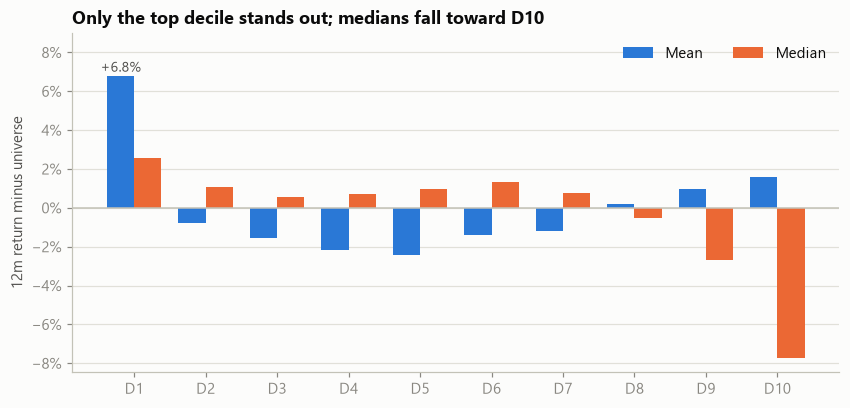

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(1, 11)
w = 0.38
ax.bar(x - w / 2, q1["Excess vs universe (mean)"], w, color=BLUE, label="Mean")
ax.bar(x + w / 2, q1["Excess vs universe (median)"], w, color=ORANGE, label="Median")
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(x, [f"D{d}" for d in x])
ax.yaxis.set_major_formatter(PCT)
lo, hi = ax.get_ylim()
ax.set_ylim(lo, hi + 0.015)
ax.annotate(f"+{q1.iloc[0, 1]:.1%}", (1 - w / 2, q1.iloc[0, 1]), xytext=(0, 3),
            textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_ylabel("12m return minus universe")
ax.set_title("Only the top decile stands out; medians fall toward D10")
ax.legend(loc="upper right", ncols=2)
plt.show()

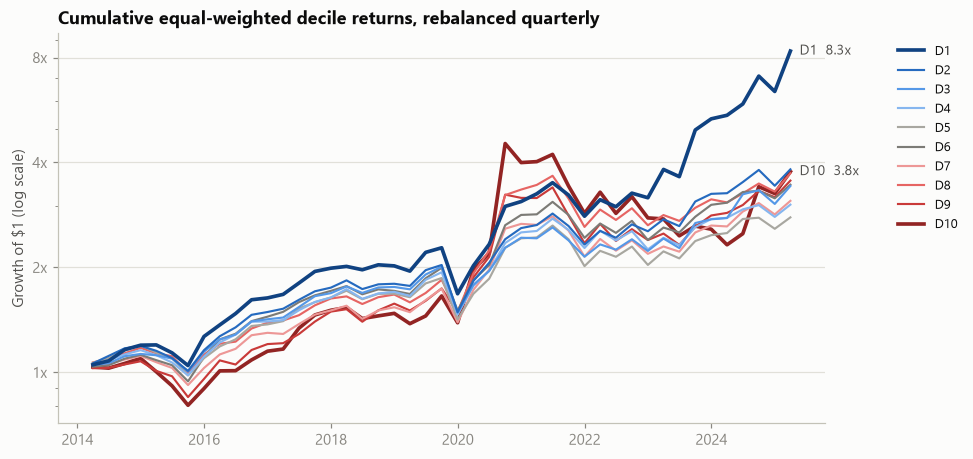

In [4]:
wealth = (1 + r3).cumprod()
fig, ax = plt.subplots(figsize=(9, 4.6))
for d in range(10, 0, -1):          # draw D1 last so it sits on top
    ax.plot(wealth.index, wealth[d], color=DECILE_COLORS[d], lw=2.4 if d in (1, 10) else 1.4,
            label=f"D{d}")
for d in (1, 10):
    ax.annotate(f"D{d}  {wealth[d].iloc[-1]:.1f}x", (wealth.index[-1], wealth[d].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.set_yscale("log")
ax.set_yticks([1, 2, 4, 8], ["1x", "2x", "4x", "8x"])
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_ylabel("Growth of $1 (log scale)")
ax.set_title("Cumulative equal-weighted decile returns, rebalanced quarterly")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.08, 1), fontsize=8.5)
plt.show()

## 2. Which features did we end up using, and how important was each?

**Answer:** 16 features were tested (13 breadth + 3 size/value). Out-of-sample backward
elimination kept **9 at 12 months** (also 9 at 6 months). By mean |SHAP| the size/value
controls are the largest contributors; among breadth features, position-size dispersion,
top-10 concentration and aggregate institutional shares lead.

SHAP size is not the same as out-of-sample usefulness: `earnings_yield` has the third-largest
SHAP value but was dropped at both horizons (removing it did not lower OOS IC), while
`delta_breadth`, the Chen–Hong–Stein predictor with one of the smallest SHAP values, was kept at
both horizons because removing it lowered IC.

*Caveats:* these values come from the README backtest, which uses the point-in-time size/value
features (Q7). Pruning is shown for transparency; the factor in this notebook uses all 16
features, because pruning on the evaluation folds would bias its IC upward.

*Method:* SHAP = mean |TreeSHAP| over out-of-sample test folds. A feature is dropped if
removing it (weakest first) does not reduce OOS mean IC.

In [5]:
r12m = json.load(open(TABLES / "backtest_results_12m.json"))
r6m = json.load(open(TABLES / "backtest_results_6m.json"))
q2 = pd.DataFrame({"Mean |SHAP| (12m)": pd.Series(r12m["shap_importance"])})
q2["Type"] = np.where(q2.index.isin(V.BASELINE_FEATURES), "size/value", "breadth")
q2["Kept (12m)"] = np.where(q2.index.isin(r12m["kept_features"]), "yes", "—")
q2["Kept (6m)"] = np.where(q2.index.isin(r6m["kept_features"]), "yes", "—")
q2 = q2.sort_values("Mean |SHAP| (12m)", ascending=False)
q2.index.name = "Feature"
q2[["Type", "Mean |SHAP| (12m)", "Kept (12m)", "Kept (6m)"]].style.format({"Mean |SHAP| (12m)": "{:.4f}"})

,Type,Mean |SHAP| (12m),Kept (12m),Kept (6m)
Feature,,,,
log_market_cap,size/value,0.0370,yes,yes
book_to_market,size/value,0.0348,yes,yes
earnings_yield,size/value,0.0337,—,—
position_size_dispersion,breadth,0.0273,yes,—
top10_share,breadth,0.0216,yes,—
log_total_inst_shares,breadth,0.0203,yes,yes
new_position_rate,breadth,0.0176,—,—
exit_rate,breadth,0.0165,—,—
hhi,breadth,0.0155,yes,yes


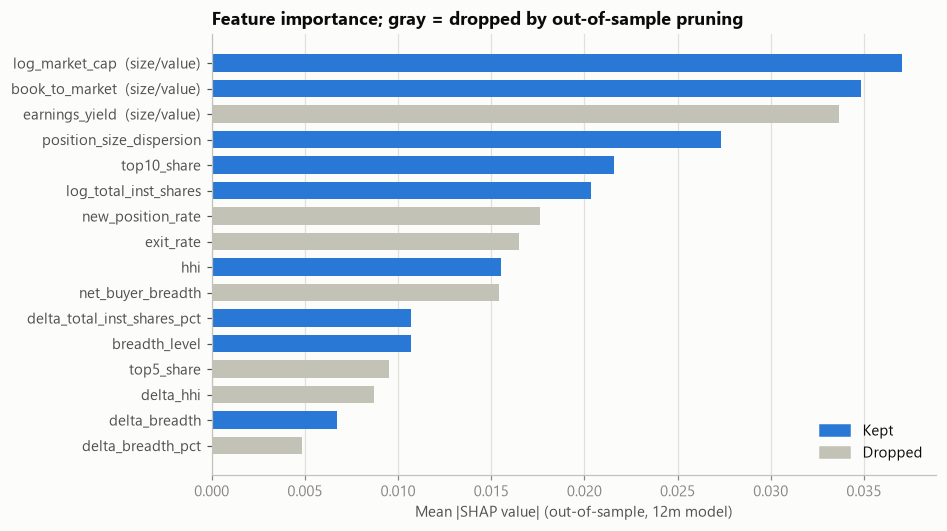

In [6]:
sh = q2.sort_values("Mean |SHAP| (12m)")
kept = sh["Kept (12m)"].eq("yes")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(sh.index, sh["Mean |SHAP| (12m)"], color=np.where(kept, BLUE, AXIS), height=0.7)
ax.set_yticks(range(len(sh)), [f"{f}  (size/value)" if t == "size/value" else f
                               for f, t in zip(sh.index, sh["Type"])])
ax.tick_params(axis="y", colors=INK2)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Mean |SHAP value| (out-of-sample, 12m model)")
ax.set_title("Feature importance; gray = dropped by out-of-sample pruning")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=AXIS)],
          labels=["Kept", "Dropped"], loc="lower right")
plt.show()

## 3. Is the breadth factor just a momentum proxy?

**Answer: no.** The factor's cross-sectional rank correlation with 12-1 momentum is about
zero (+0.01; +0.07 for the breadth-only model). After stripping momentum out of the score each
quarter, 90% of the IC remains (0.062 → 0.055 for the factor, 0.048 → 0.042 for breadth-only),
all with t > 4. Momentum itself had essentially no 12-month IC in this sample.

**Size is the bigger overlap.** The breadth-only score has a 0.46 rank correlation with
point-in-time market cap, since more institutional holders goes with bigger companies. On names
with a trustworthy cap, its IC drops from 0.021 to 0.010 (t ≈ 1.2) once size is removed.
Breadth's independent contribution is therefore about 0.01 IC, consistent with its +0.0095
increment over the size/value baseline.

*Method:* 12-1 momentum = return from 12 months to 1 month before formation, using only
prices on or before those dates. "Neutralised" = residual of the score's rank regressed on the
control's rank, per quarter. Each comparison uses the same stocks before and after.

In [7]:
m = vp.dropna(subset=["mom_12_1"]).copy()
for col in ("score_full", "score_breadth"):
    m[col + "_xmom"] = V.neutralize(m, col, ["mom_12_1"])

def avg_corr(df, a, b):
    return df.groupby("period").apply(lambda g: stats.spearmanr(g[a], g[b])[0]).mean()

rows = {
    "12-1 momentum": ("mom_12_1", np.nan),
    "Factor (breadth + size/value)": ("score_full", avg_corr(m, "score_full", "mom_12_1")),
    "Factor, momentum-neutral": ("score_full_xmom", np.nan),
    "Breadth-only model": ("score_breadth", avg_corr(m, "score_breadth", "mom_12_1")),
    "Breadth-only, momentum-neutral": ("score_breadth_xmom", np.nan),
}
q3 = pd.DataFrame({name: {**ic_summary(rank_ic(m, col, "fwd_ret_12m")), "Corr. with momentum": c}
                   for name, (col, c) in rows.items()}).T
q3 = q3.rename(columns={"mean_ic": "Mean IC", "t_stat": "t-stat", "icir": "ICIR",
                        "hit_rate": "% quarters IC > 0"})
q3 = q3[["Mean IC", "t-stat", "ICIR", "% quarters IC > 0", "Corr. with momentum"]]
q3.index.name = "Signal (12m forward return)"

# Size check for the breadth-only score, on names with a trustworthy point-in-time cap.
z = vp[vp["cap_ok"]].copy()
z["log_cap"] = np.log(z["market_cap"])
z["breadth_xsize"] = V.neutralize(z, "score_breadth", ["log_cap"])
b, bx = (ic_summary(rank_ic(z, c, "fwd_ret_12m")) for c in ("score_breadth", "breadth_xsize"))
print(f"Breadth-only vs size: rank corr {avg_corr(z, 'score_breadth', 'log_cap'):.2f}; "
      f"IC {b['mean_ic']:.3f} -> {bx['mean_ic']:.3f} after removing size (t {bx['t_stat']:.1f}), "
      f"on {len(z):,} stock-quarters with a sane cap")
q3.style.format({"Mean IC": "{:.3f}", "t-stat": "{:.1f}", "ICIR": "{:.2f}",
                 "% quarters IC > 0": "{:.0%}", "Corr. with momentum": "{:+.2f}"}, na_rep="")

Breadth-only vs size: rank corr 0.46; IC 0.021 -> 0.010 after removing size (t 1.2), on 96,942 stock-quarters with a sane cap


,Mean IC,t-stat,ICIR,% quarters IC > 0,Corr. with momentum
Signal (12m forward return),,,,,
12-1 momentum,0.005,0.3,0.04,56%,
Factor (breadth + size/value),0.062,5.5,0.81,78%,+0.01
"Factor, momentum-neutral",0.055,5.0,0.75,78%,
Breadth-only model,0.048,5.1,0.76,80%,+0.07
"Breadth-only, momentum-neutral",0.042,4.5,0.67,73%,


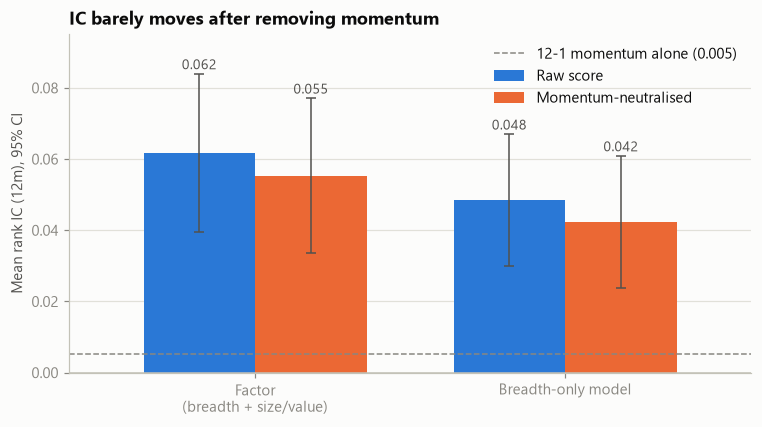

In [8]:
def ci95(col):
    ic = rank_ic(m, col, "fwd_ret_12m")
    return ic.mean(), 1.96 * ic.std(ddof=1) / np.sqrt(len(ic))

groups = [("Factor\n(breadth + size/value)", "score_full"), ("Breadth-only model", "score_breadth")]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(groups)); w = 0.36
for k, (lab, suffix, color) in enumerate([("Raw score", "", BLUE), ("Momentum-neutralised", "_xmom", ORANGE)]):
    vals = [ci95(col + suffix) for _, col in groups]
    bars = ax.bar(x + (k - 0.5) * w, [v for v, _ in vals], w, yerr=[e for _, e in vals],
                  color=color, label=lab, error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
    for bar, (v, e) in zip(bars, vals):
        ax.annotate(f"{v:.3f}", (bar.get_x() + bar.get_width() / 2, v + e), xytext=(0, 3),
                    textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_xlim(-0.6, len(groups) - 0.4)
mom_ic = rank_ic(m, "mom_12_1", "fwd_ret_12m").mean()
ax.axhline(mom_ic, color=MUTED, ls="--", lw=1, label=f"12-1 momentum alone ({mom_ic:.3f})")
ax.axhline(0, color=AXIS, lw=1)
ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
ax.set_xticks(x, [g for g, _ in groups])
ax.set_ylabel("Mean rank IC (12m), 95% CI")
ax.set_title("IC barely moves after removing momentum")
ax.legend(loc="upper right")
plt.show()

## 4. Does the factor work better in some regimes than others?

**Answer: it worked better when rates were rising.** IC averaged 0.089 in the 24 quarters
where the 10-year Treasury yield was higher than a year earlier, versus 0.036 in the 21
quarters where it was lower (Welch p ≈ 0.03). The level of rates (above vs below the sample
median) makes no difference (p ≈ 0.7). Treat the trend result as suggestive: adjacent quarters'
12-month returns overlap, so the p-value overstates the evidence, and falling-rate quarters
cluster in three episodes (mid-2014–2016, 2019–early 2021 and late 2024). The factor's average IC was positive in every bucket.

*Method:* 10-year yield (`^TNX`) observed on or before each formation date. This is a
descriptive split, not a timing signal.

In [9]:
fd = vp.groupby("period")["formation_date"].first()
regimes = V.rate_regimes(fd, V.load_macro_series(cfg, "^TNX")).set_index("formation_date")
ics = pd.DataFrame({"Factor": ic_factor.values,
                    "Breadth-only": rank_ic(vp, "score_breadth", "fwd_ret_12m").values},
                   index=pd.to_datetime(fd.loc[ic_factor.index].values)).join(regimes)

rows = []
for col, order in [("trend", ["Rising rates", "Falling rates"]), ("level", ["High rates", "Low rates"])]:
    for lab in order:
        g = ics[ics[col] == lab]
        rows.append({"Split": "Trend (vs 12m ago)" if col == "trend" else "Level (vs median)",
                     "Regime": lab, "Quarters": len(g),
                     "Mean IC (factor)": g["Factor"].mean(),
                     "t-stat": g["Factor"].mean() / (g["Factor"].std(ddof=1) / np.sqrt(len(g))),
                     "Mean IC (breadth-only)": g["Breadth-only"].mean()})
q4 = pd.DataFrame(rows).set_index(["Split", "Regime"])
for col, (a, b) in [("trend", ("Rising rates", "Falling rates")), ("level", ("High rates", "Low rates"))]:
    p = stats.ttest_ind(ics.loc[ics[col] == a, "Factor"], ics.loc[ics[col] == b, "Factor"],
                        equal_var=False).pvalue
    print(f"{a} vs {b}: difference in mean IC, Welch p = {p:.3f}")
q4.style.format({"Mean IC (factor)": "{:.3f}", "t-stat": "{:.1f}", "Mean IC (breadth-only)": "{:.3f}"})

Rising rates vs Falling rates: difference in mean IC, Welch p = 0.025
High rates vs Low rates: difference in mean IC, Welch p = 0.721


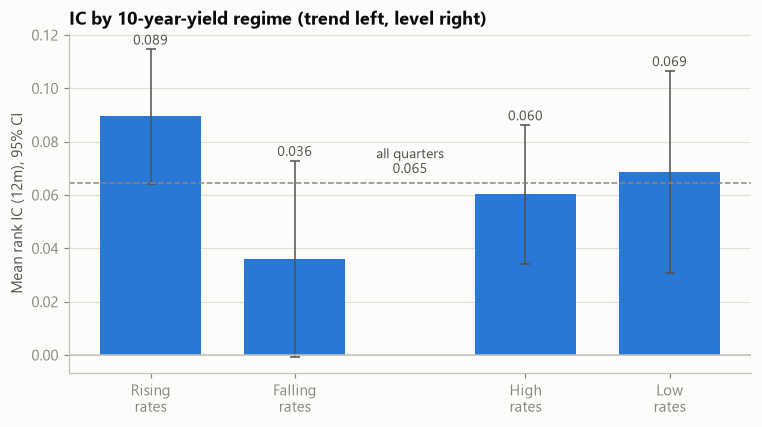

In [10]:
labels = [r for _, r in q4.index]
means = q4["Mean IC (factor)"].to_numpy()
errs = 1.96 * means / q4["t-stat"].to_numpy()           # 1.96 x standard error
pos = np.array([0, 1, 2.6, 3.6])
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(pos, means, 0.7, yerr=errs, color=BLUE,
              error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
for bar, v, e in zip(bars, means, errs):
    ax.annotate(f"{v:.3f}", (bar.get_x() + bar.get_width() / 2, v + e), xytext=(0, 3),
                textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.axhline(ic_factor.mean(), color=MUTED, ls="--", lw=1)
ax.annotate(f"all quarters\n{ic_factor.mean():.3f}", (1.8, ic_factor.mean()), xytext=(0, 4),
            textcoords="offset points", ha="center", va="bottom", color=INK2, fontsize=9)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(pos, [l.replace(" ", "\n") for l in labels])
ax.set_ylabel("Mean rank IC (12m), 95% CI")
ax.set_title("IC by 10-year-yield regime (trend left, level right)")
plt.show()

## 5. Are the deciles stable from quarter to quarter?

**Answer: the extremes are sticky, the middle churns.** D1 keeps 55% of its names into the
next quarter and D10 keeps 48%, versus about 21% for the middle deciles (10% would be pure chance).
Even so, about 128 of D1's ~288 names are replaced every quarter (~44% one-way turnover,
~175% a year), so trading costs would materially reduce a live version of this factor.
Most moves are to a neighbouring decile; fewer than 1% of names jump from one end to the other.

*Notes:* "Left universe" = no longer scored next quarter (fewer than 5 holders, delisted, or
merged). Four of the 44 transitions cross a CV-fold boundary, where a different model scores
the next quarter; D1 retention there is 35% versus 57% within a fold, so the averages slightly
overstate true turnover.

In [11]:
flows = V.decile_flows(vp)
g = flows.groupby("decile")
q5 = pd.DataFrame({
    "Avg names": g["size"].mean(),
    "Avg entering / qtr": g["entered"].mean(),
    "Avg leaving / qtr": g["left"].mean(),
    "Stayed in decile": g["retained"].sum() / g["prior_size"].sum(),
})
q5.index = [f"D{d}" for d in q5.index]
q5.index.name = "Decile"
for cross, lab in [(False, "within a CV fold"), (True, "across a CV-fold boundary")]:
    f = flows[(flows.cross_fold == cross) & (flows.decile == 1)]
    print(f"D1 retention {lab}: {f.retained.sum() / f.prior_size.sum():.0%} "
          f"({f.period.nunique()} transitions)")
q5.style.format({"Avg names": "{:.0f}", "Avg entering / qtr": "{:.0f}",
                 "Avg leaving / qtr": "{:.0f}", "Stayed in decile": "{:.0%}"})

D1 retention within a CV fold: 57% (40 transitions)
D1 retention across a CV-fold boundary: 35% (4 transitions)


,Avg names,Avg entering / qtr,Avg leaving / qtr,Stayed in decile
Decile,,,,
D1,288,133,128,55%
D2,287,201,196,31%
D3,287,221,216,23%
D4,287,227,222,21%
D5,287,229,224,21%
D6,287,228,223,21%
D7,287,223,218,23%
D8,287,210,205,27%
D9,287,195,190,33%


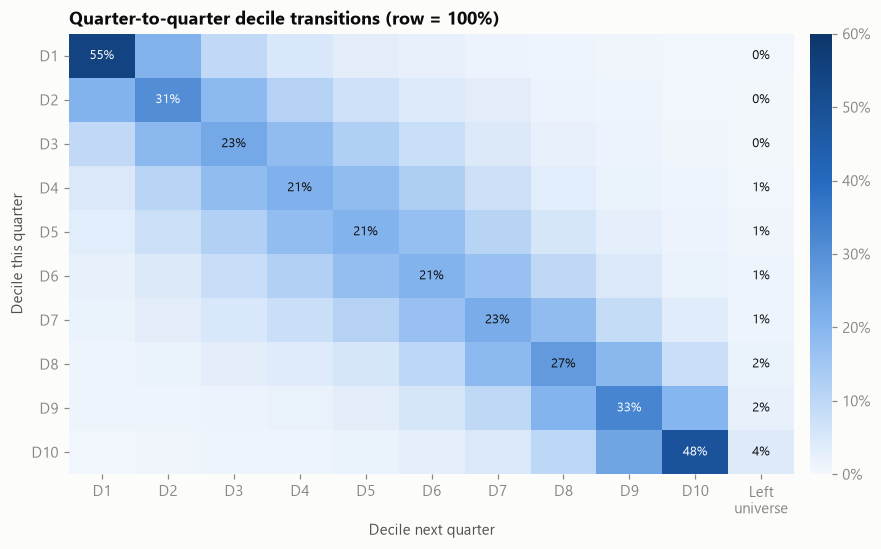

In [12]:
tm = V.transition_matrix(vp)
cmap = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#86b6ef", "#256abf", "#0d366b"])
fig, ax = plt.subplots(figsize=(9, 5.2))
im = ax.imshow(tm.to_numpy(), cmap=cmap, vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(tm.shape[1]), [f"D{c}" if c != "Left universe" else "Left\nuniverse" for c in tm.columns])
ax.set_yticks(range(tm.shape[0]), [f"D{r}" for r in tm.index])
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(tm.shape[0]):               # label the diagonal and the exit column only
    for j in (i, tm.shape[1] - 1):
        v = tm.iat[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.3 else INK)
ax.set_xlabel("Decile next quarter")
ax.set_ylabel("Decile this quarter")
ax.set_title("Quarter-to-quarter decile transitions (row = 100%)")
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, format=PCT)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED)
plt.show()

## 6. Cap-weighted vs equal-weighted top-minus-bottom decile

**Answer: the long-short doesn't work reliably either way; the long leg does.** A quarterly
D1 − D10 portfolio earns about +4% a year equal-weighted, with 30% volatility (not significant).
On the names with a trustworthy market cap, both equal- and cap-weighted versions lose about 7%
a year. In every version, though, D1 beats its own universe (see the D1 and universe columns).
The short leg is the problem: D10 is mostly micro-caps (median $0.23bn) whose occasional
explosive rallies, such as the late-2020 meme and crypto run, overwhelm a short position.
Survivorship bias in the free price data also flatters those micro-caps.
The usable edge is **long-only**, not market-neutral.

*Assumptions:* dollar-neutral, long D1 and short D10 (deciles formed on the full universe),
rebalanced quarterly with a 3-month hold, gross of trading and borrow costs. Cumulative
returns are summed rather than compounded (a short leg can lose more than 100% in a quarter).
Cap weights use formation-date **as-traded** price × SEC-XBRL shares outstanding, restricted to
caps that pass the checks in Q7–Q8 (76% of stock-quarters). Equal-weighted results are shown both
on all names and on that same subset, so the comparison is like-for-like.

In [13]:
clean = vp[vp["cap_ok"]]
def univ(df, weight=None):
    d = df.dropna(subset=["fwd_ret_3m"] + ([weight] if weight else []))
    if weight is None:
        return d.groupby("period")["fwd_ret_3m"].mean()
    return (d["fwd_ret_3m"] * d[weight]).groupby(d["period"]).sum() / d[weight].groupby(d["period"]).sum()

variants = {
    "Equal-weighted, all names": (V.decile_returns(vp, "fwd_ret_3m"), univ(vp)),
    "Equal-weighted, sane-cap names": (V.decile_returns(clean, "fwd_ret_3m"), univ(clean)),
    "Cap-weighted, sane-cap names": (V.decile_returns(clean, "fwd_ret_3m", weight_col="market_cap"),
                                     univ(clean, "market_cap")),
}
ls = {k: d[1] - d[10] for k, (d, _) in variants.items()}
q6 = pd.DataFrame({k: {**V.long_short_stats(ls[k]),
                       "Long D1 (ann.)": d[1].mean() * 4,
                       "Universe (ann.)": u.mean() * 4,
                       "Short D10 (ann.)": d[10].mean() * 4} for k, (d, u) in variants.items()}).T
q6 = q6[["Ann. return", "Ann. vol", "Sharpe", "t-stat", "Worst quarter", "% quarters > 0",
         "Long D1 (ann.)", "Universe (ann.)", "Short D10 (ann.)"]]
q6.index.name = "D1 − D10, quarterly rebalance"
print("Median point-in-time cap: D1", money(clean.loc[clean.decile == 1, "market_cap"].median()),
      "| D10", money(clean.loc[clean.decile == 10, "market_cap"].median()))
q6.style.format({c: "{:.1%}" for c in q6.columns if c not in ("Sharpe", "t-stat")} |
                {"Sharpe": "{:.2f}", "t-stat": "{:.1f}"})

Median point-in-time cap: D1 $4.7bn | D10 $230.8m


,Ann. return,Ann. vol,Sharpe,t-stat,Worst quarter,% quarters > 0,Long D1 (ann.),Universe (ann.),Short D10 (ann.)
"D1 − D10, quarterly rebalance",,,,,,,,,
"Equal-weighted, all names",4.2%,30.0%,0.14,0.5,-77.9%,64.4%,21.8%,14.0%,17.6%
"Equal-weighted, sane-cap names",-6.8%,47.8%,-0.14,-0.5,-140.8%,55.6%,21.8%,15.6%,28.6%
"Cap-weighted, sane-cap names",-7.0%,30.4%,-0.23,-0.8,-82.2%,51.1%,16.2%,13.1%,23.1%


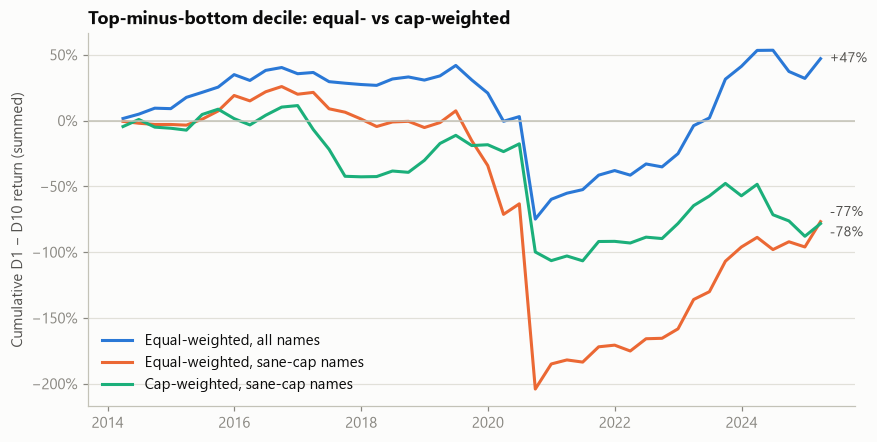

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.4))
cums = {name: r.cumsum() for name, r in ls.items()}
for (name, c), color in zip(cums.items(), [BLUE, ORANGE, AQUA]):
    ax.plot(c.index, c.values, color=color, label=name)
# End labels, nudged apart when two lines finish close together.
ends = sorted((c.iloc[-1], name) for name, c in cums.items())
span = max(ends)[0] - min(ends)[0]
for k, (v, name) in enumerate(ends):
    close_below = k > 0 and v - ends[k - 1][0] < 0.08 * span
    close_above = k < len(ends) - 1 and ends[k + 1][0] - v < 0.08 * span
    dy = -6 if close_above else (6 if close_below else 0)
    ax.annotate(f"{v:+.0%}", (cums[name].index[-1], v), xytext=(6, dy),
                textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.axhline(0, color=AXIS, lw=1)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel("Cumulative D1 − D10 return (summed)")
ax.set_title("Top-minus-bottom decile: equal- vs cap-weighted")
ax.legend(loc="lower left")
plt.show()

## 7. Are the size/value inputs point-in-time?

**Answer: now yes — but originally they were not, and that was a real look-ahead.** Phase 4
first computed market cap as yfinance's *adjusted* close × the XBRL share count. Adjusted prices
are rescaled backwards for every later split and dividend, so a stock that later splits 20-for-1
looks 20× smaller on earlier dates. Because stocks split *after* rising, future winners looked
small and cheap at formation. 10% of stock-quarters had caps understated by at least 1.5×, and 5%
by at least 2× (e.g. AMZN 20× and NVDA 39× at end-2019). The understatement alone predicts
12-month returns (IC ≈ 0.05).

**Fix and impact:** Phase 4 now builds `log_market_cap`, `book_to_market` and `earnings_yield`
from as-traded prices (and drops caps that fail the Q8 check). The table replays the old
features next to the current ones on identical folds: the baseline IC falls from 0.062 to 0.055
and the full model's from 0.072 to 0.0645, while the **incremental IC from breadth is unchanged
at +0.0095**. The look-ahead had flattered the size/value controls, not the breadth signal.

*Method:* as-traded price = yfinance close (not dividend-adjusted, still split-adjusted)
multiplied by all splits after the date, using the last close on or before the formation date.
The "look-ahead" column rebuilds the old features exactly (adjusted close × the same share
count, no share-count check) and is kept only for this comparison.

In [15]:
ic_tab = pd.DataFrame({
    "Look-ahead (pre-fix)": [ic_summary(rank_ic(vp, c, "fwd_ret_12m"))["mean_ic"]
                             for c in ("score_baseline_lookahead", "score_full_lookahead")],
    "Point-in-time (Phase 4 now)": [ic_summary(rank_ic(vp, c, "fwd_ret_12m"))["mean_ic"]
                                    for c in ("score_baseline", "score_full")],
}, index=["Size/value baseline", "Full model (breadth + size/value)"])
ic_tab.loc["Incremental IC from breadth"] = ic_tab.iloc[1] - ic_tab.iloc[0]
ic_tab.index.name = "Mean rank IC, 12m"
leak = vp.dropna(subset=["market_cap", "market_cap_lookahead"]).assign(
    understated=lambda d: np.log(d["market_cap"] / d["market_cap_lookahead"]))
lk = ic_summary(rank_ic(leak, "understated", "fwd_ret_12m"))
print(f"IC of the understatement itself vs 12m return: {lk['mean_ic']:.3f} (t {lk['t_stat']:.1f})")
display(ic_tab.style.format("{:.4f}"))

ex = vp[(vp.period == pd.Timestamp("2019-12-31")) & vp.ticker.isin(["AAPL", "AMZN", "NVDA", "TSLA", "NFLX", "MSFT"])]
ex = ex.assign(ratio=ex["market_cap"] / ex["market_cap_lookahead"]).sort_values("ratio", ascending=False)
pd.DataFrame({"Ticker": ex["ticker"], "Look-ahead cap (pre-fix)": ex["market_cap_lookahead"].map(money),
              "Point-in-time cap": ex["market_cap"].map(money),
              "Understated by": ex["ratio"].map("{:.1f}x".format)}).style.hide(axis="index")     .set_caption("Formation 2020-02-15 (period 2019-Q4)")

IC of the understatement itself vs 12m return: 0.055 (t 2.7)


,Look-ahead (pre-fix),Point-in-time (Phase 4 now)
"Mean rank IC, 12m",,
Size/value baseline,0.0620,0.0550
Full model (breadth + size/value),0.0716,0.0645
Incremental IC from breadth,0.0095,0.0095


Ticker,Look-ahead cap (pre-fix),Point-in-time cap,Understated by
NVDA,$4.5bn,$177.4bn,39.3x
AMZN,$53.7bn,$1.1T,19.8x
TSLA,$10.4bn,$145.1bn,14.0x
NFLX,$17.0bn,$166.9bn,9.8x
AAPL,$336.9bn,$1.4T,4.2x
MSFT,$1.3T,$1.4T,1.0x


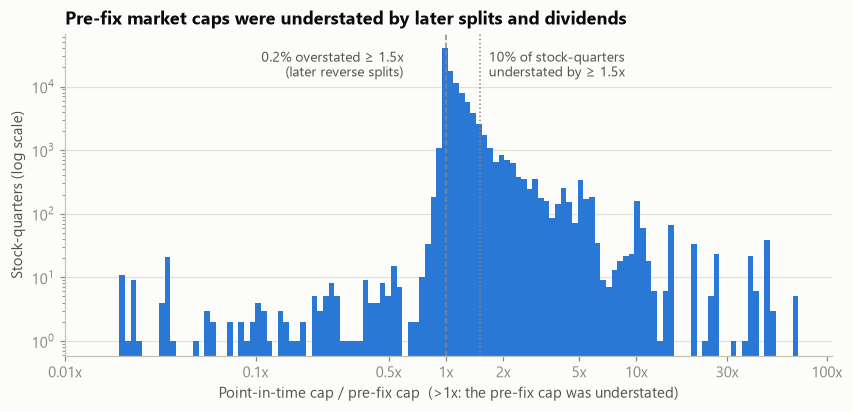

In [16]:
both = vp.dropna(subset=["market_cap", "market_cap_lookahead"])
ratio = np.log10(both["market_cap"] / both["market_cap_lookahead"]).clip(-2, 2)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(ratio, bins=120, color=BLUE)
ax.set_yscale("log")
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.axvline(np.log10(1.5), color=MUTED, ls=":", lw=1)
share = (both["market_cap"] / both["market_cap_lookahead"] >= 1.5).mean()
ax.annotate(f"{share:.0%} of stock-quarters\nunderstated by ≥ 1.5x", (np.log10(1.5), ax.get_ylim()[1]),
            xytext=(6, -28), textcoords="offset points", color=INK2, fontsize=9)
over = (both["market_cap"] / both["market_cap_lookahead"] <= 1 / 1.5).mean()
ax.annotate(f"{over:.1%} overstated ≥ 1.5x\n(later reverse splits)", (np.log10(1 / 1.5), ax.get_ylim()[1]),
            xytext=(-6, -28), textcoords="offset points", ha="right", color=INK2, fontsize=9)
ticks = [0.01, 0.1, 0.5, 1, 2, 5, 10, 30, 100]
ax.set_xticks(np.log10(ticks), [f"{t:g}x" for t in ticks])
ax.set_xlabel("Point-in-time cap / pre-fix cap  (>1x: the pre-fix cap was understated)")
ax.set_ylabel("Stock-quarters (log scale)")
ax.set_title("Pre-fix market caps were understated by later splits and dividends")
plt.show()

## 8. Are the SEC share counts sane?

**Answer: mostly, with a tail of bad ones.** 2.8% of stock-quarters with a share count (466 tickers)
fail a consistency check against 13F holdings. Two causes are visible. **ADRs**: the price is
per ADR but XBRL reports *ordinary* shares, so issuers like Toyota, HSBC, Vodafone and Diageo come
out several times too large (Toyota at about $2.5T). **Filing scale errors**: e.g. BTI implies a
cap of about $93,000 *trillion*, and some issuers, such as FOXA, come out implausibly small. Phase 4 now
applies this check: these rows get missing size/value features (LightGBM treats them as
unknown rather than wrong), and Q6 excludes them.

*Check:* the implied institutional-ownership ratio (13F shares held ÷ XBRL shares outstanding)
should lie between 1% and 300%, because 13F holdings independently count the same shares.
Point-in-time caps above $6T are also rejected. The 1% floor is deliberately conservative: it
also drops some foreign issuers whose caps are roughly right but whose shares sit mostly with
holders who don't file 13Fs.

In [17]:
lo, hi = V.IO_RATIO_BOUNDS
has = vp.dropna(subset=["io_ratio"])
bad = has[~has["io_ratio"].between(lo, hi) | (has["market_cap"] > V.MCAP_MAX)]
print(f"{len(bad):,} of {len(has):,} stock-quarters with a share count fail ({len(bad) / len(has):.1%}), "
      f"{bad.ticker.nunique()} tickers")
worst = (bad.assign(dist=np.abs(np.log10(bad["io_ratio"])))
            .sort_values("dist", ascending=False).drop_duplicates("ticker").head(6))
adrs = (bad[bad.ticker.isin(["TM", "HSBC", "VOD", "DEO"])]
        .sort_values("period", ascending=False).drop_duplicates("ticker"))   # latest flagged quarter
show = pd.concat([worst, adrs])
pd.DataFrame({"Ticker": show["ticker"], "Quarter": show["period"].dt.strftime("%Y-%m"),
              "Implied cap": show["market_cap"].fillna(show["market_cap_lookahead"]).map(money),
              "13F shares / XBRL shares": show["io_ratio"].map("{:.2g}".format)}).style.hide(axis="index")

2,808 of 101,224 stock-quarters with a share count fail (2.8%), 466 tickers


Ticker,Quarter,Implied cap,13F shares / XBRL shares
FOXA,2020-06,$26,3.5e+08
FOX,2019-09,$34,1.4e+08
BTI,2020-12,"$93,421.5T",3.6e-08
CUBI,2014-09,$19,2e+07
CIA,2020-03,$5,1.2e+07
VTRS,2020-12,$1.8k,6.6e+06
VOD,2025-03,$272.3bn,0.0075
HSBC,2025-03,$1.1T,0.0042
TM,2025-03,$2.5T,0.0017
DEO,2021-09,$524.7bn,0.0099


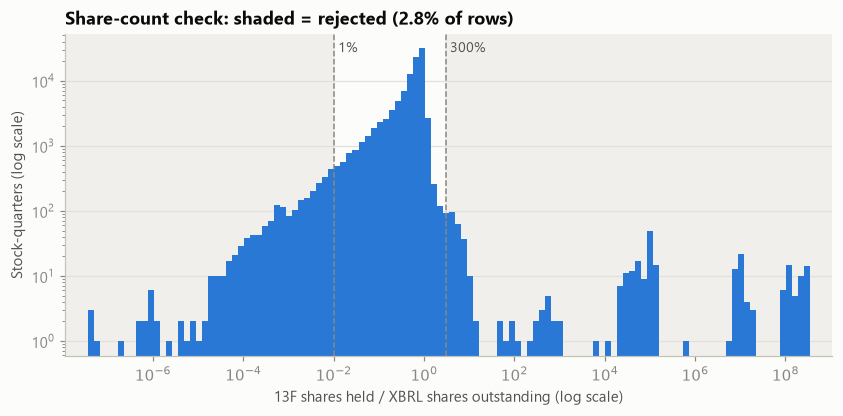

In [18]:
x = np.log10(has["io_ratio"].clip(1e-9, 1e9))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvspan(x.min() - 0.5, np.log10(lo), color="#f0efec", zorder=0)
ax.axvspan(np.log10(hi), x.max() + 0.5, color="#f0efec", zorder=0)
ax.hist(x, bins=120, color=BLUE)
ax.set_yscale("log")
for b, lab in [(lo, f"{lo:.0%}"), (hi, f"{hi:.0%}")]:
    ax.axvline(np.log10(b), color=MUTED, ls="--", lw=1)
    ax.annotate(lab, (np.log10(b), ax.get_ylim()[1]), xytext=(3, -12), textcoords="offset points",
                color=INK2, fontsize=9)
ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"$10^{{{v:.0f}}}$"))
ax.set_xlabel("13F shares held / XBRL shares outstanding (log scale)")
ax.set_ylabel("Stock-quarters (log scale)")
ax.set_title(f"Share-count check: shaded = rejected ({len(bad) / len(has):.1%} of rows)")
plt.show()